In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450

In [3]:
print("Shape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all"))

Shape of dataset:
(891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical summary:
        PassengerId    Survived      Pcl

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nMissing value percentage:")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing value percentage:
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [6]:
df = df.drop_duplicates()

print("Shape after removing duplicates:")
print(df.shape)

Shape after removing duplicates:
(891, 12)


In [7]:
print(df[["Age", "Cabin", "Embarked"]].isnull().sum())

Age         177
Cabin       687
Embarked      2
dtype: int64


In [8]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [9]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [10]:
df = df.drop(columns=["Cabin"])

In [11]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [12]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object


In [13]:
df["Survived"] = df["Survived"].astype(int)
df["Pclass"] = df["Pclass"].astype(int)
df["SibSp"] = df["SibSp"].astype(int)
df["Parch"] = df["Parch"].astype(int)

In [14]:
df["Sex"] = df["Sex"].astype("category")
df["Embarked"] = df["Embarked"].astype("category")

In [15]:
print("Unique values in Sex:")
print(df["Sex"].unique())

print("\nUnique values in Embarked:")
print(df["Embarked"].unique())

print("\nAge range:")
print(df["Age"].min(), "to", df["Age"].max())

Unique values in Sex:
['male', 'female']
Categories (2, object): ['female', 'male']

Unique values in Embarked:
['S', 'C', 'Q']
Categories (3, object): ['C', 'Q', 'S']

Age range:
0.42 to 80.0


In [16]:
df["Sex"] = df["Sex"].map({
    "male": 0,
    "female": 1
})

df["Embarked"] = df["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

In [17]:
print(df.head())
print(df.dtypes)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris   0  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   1  38.0      1      0   
2                             Heikkinen, Miss. Laina   1  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   1  35.0      1      0   
4                           Allen, Mr. William Henry   0  35.0      0      0   

             Ticket     Fare Embarked  
0         A/5 21171   7.2500        0  
1          PC 17599  71.2833        1  
2  STON/O2. 3101282   7.9250        0  
3            113803  53.1000        0  
4            373450   8.0500        0  
PassengerId       int64
Survived          int64
Pclass        

In [18]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [19]:
df["IsAlone"] = np.where(df["FamilySize"] == 1, 1, 0)

In [20]:
print(df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head())

   SibSp  Parch  FamilySize  IsAlone
0      1      0           2        0
1      1      0           2        0
2      0      0           1        1
3      1      0           2        0
4      0      0           1        1


In [21]:
df = df.drop(columns=["Name", "Ticket", "PassengerId"])

In [22]:
print("Final missing values:")
print(df.isnull().sum())

Final missing values:
Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
IsAlone       0
dtype: int64


In [23]:
print("\nFinal Dataset Shape:")
print(df.shape)

print("\nFinal Dataset Information:")
df.info()

print("\nFirst 10 rows:")
print(df.head(10))


Final Dataset Shape:
(891, 10)

Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    891 non-null    int64   
 1   Pclass      891 non-null    int64   
 2   Sex         891 non-null    category
 3   Age         891 non-null    float64 
 4   SibSp       891 non-null    int64   
 5   Parch       891 non-null    int64   
 6   Fare        891 non-null    float64 
 7   Embarked    891 non-null    category
 8   FamilySize  891 non-null    int64   
 9   IsAlone     891 non-null    int64   
dtypes: category(2), float64(2), int64(6)
memory usage: 57.8 KB

First 10 rows:
   Survived  Pclass Sex   Age  SibSp  Parch     Fare Embarked  FamilySize  \
0         0       3   0  22.0      1      0   7.2500        0           2   
1         1       1   1  38.0      1      0  71.2833        1           2   
2         1       3 

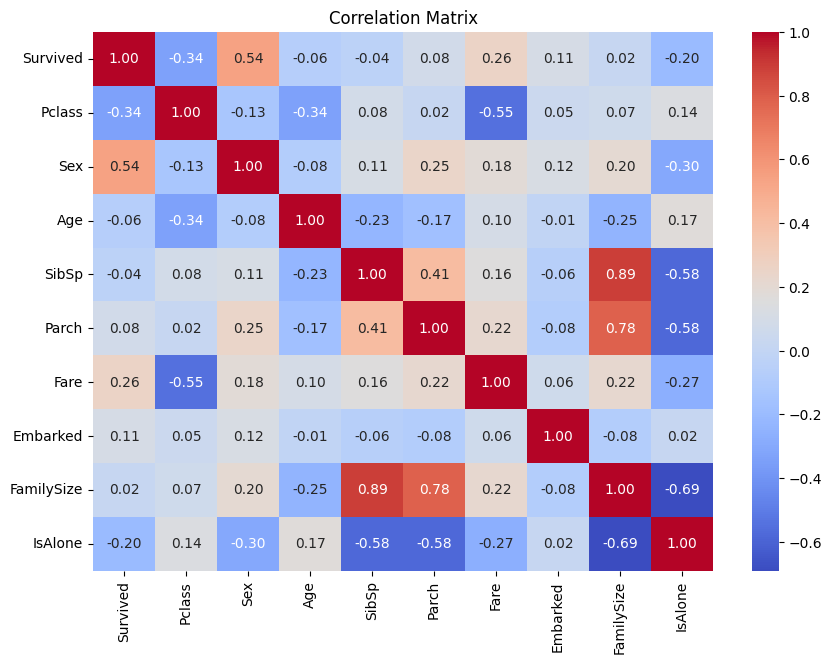

In [24]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

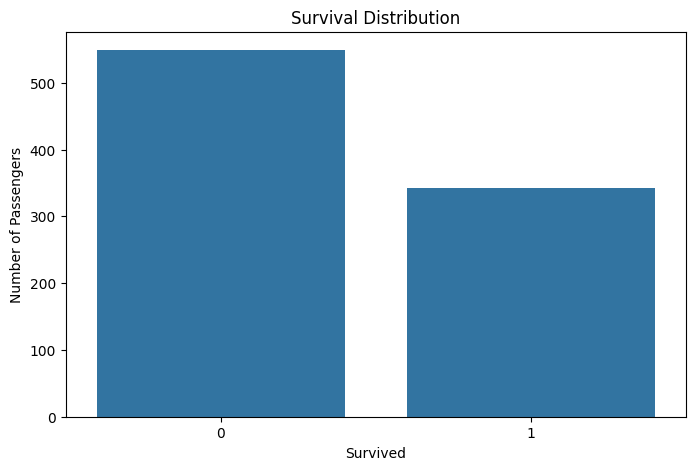

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Survived"
)

plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

In [26]:
output_file = "titanic_cleaned.csv"

df.to_csv(output_file, index=False)

print(f"Cleaned dataset saved as: {output_file}")

Cleaned dataset saved as: titanic_cleaned.csv


In [27]:
cleaned_df = pd.read_csv("titanic_cleaned.csv")

print("Cleaned dataset successfully loaded!")
print(cleaned_df.head())
print("\nShape:", cleaned_df.shape)

Cleaned dataset successfully loaded!
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked  FamilySize  \
0         0       3    0  22.0      1      0   7.2500         0           2   
1         1       1    1  38.0      1      0  71.2833         1           2   
2         1       3    1  26.0      0      0   7.9250         0           1   
3         1       1    1  35.0      1      0  53.1000         0           2   
4         0       3    0  35.0      0      0   8.0500         0           1   

   IsAlone  
0        0  
1        0  
2        1  
3        0  
4        1  

Shape: (891, 10)


Dataset loaded successfully!
Original Shape: (891, 12)

First 5 rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C

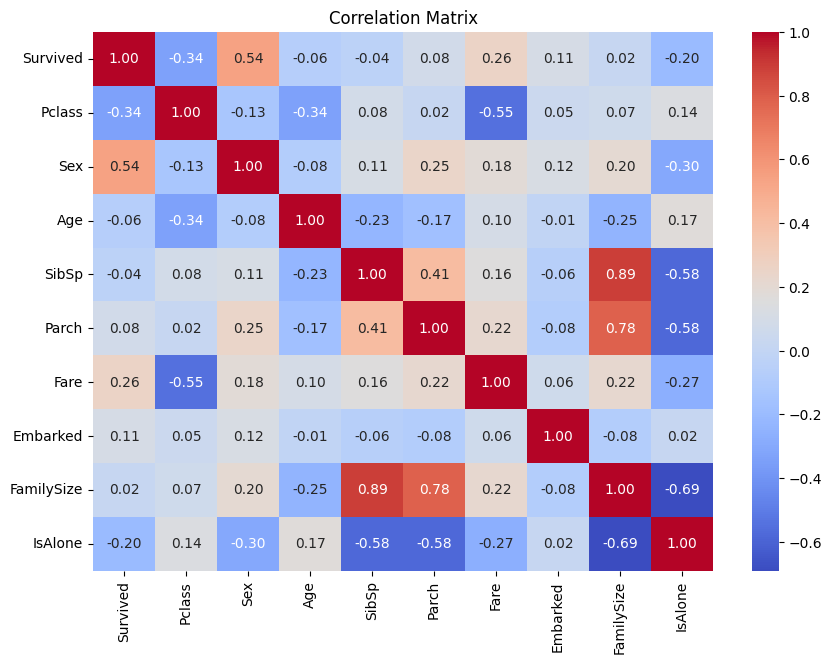

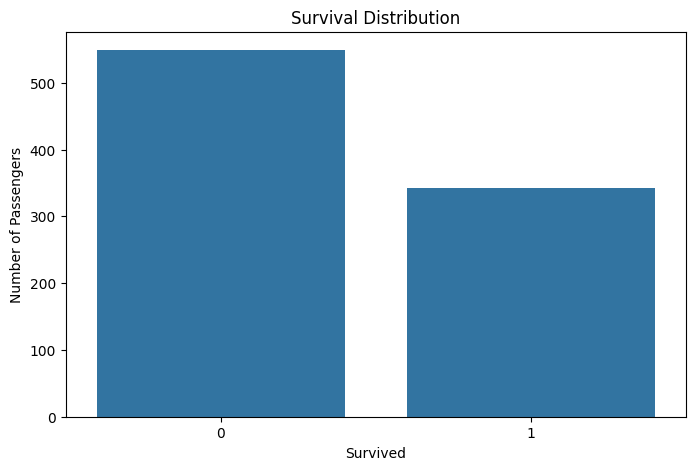


Cleaned dataset saved successfully!
File: titanic_cleaned.csv


In [28]:
# ==========================================
# DATA PREPARATION - TITANIC DATASET
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load public dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Original Shape:", df.shape)

# 2. Inspect dataset
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))

# 3. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Remove duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

# 5. Handle missing values

# Fill Age with median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill Embarked with mode
df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0]
)

# Drop Cabin because it contains many missing values
df = df.drop(columns=["Cabin"])

# 6. Handle data types
df["Survived"] = df["Survived"].astype(int)
df["Pclass"] = df["Pclass"].astype(int)
df["SibSp"] = df["SibSp"].astype(int)
df["Parch"] = df["Parch"].astype(int)

# 7. Encode categorical columns
df["Sex"] = df["Sex"].map({
    "male": 0,
    "female": 1
})

df["Embarked"] = df["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

# 8. Feature engineering
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = np.where(
    df["FamilySize"] == 1,
    1,
    0
)

# 9. Remove unnecessary columns
df = df.drop(
    columns=["Name", "Ticket", "PassengerId"]
)

# 10. Final missing-value check
print("\nFinal Missing Values:")
print(df.isnull().sum())

# 11. Final dataset information
print("\nFinal Dataset Shape:")
print(df.shape)

print("\nFinal Dataset:")
print(df.head())

print("\nFinal Data Types:")
print(df.dtypes)

# 12. Correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# 13. Survival visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Survived"
)

plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

# 14. Save cleaned dataset
df.to_csv(
    "titanic_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")
print("File: titanic_cleaned.csv")